# 03 · Decoding, Adaptation & Evaluation
**Group 7 · PCAM ZG516 Applied Generative AI · SQuAD v2 "Answer-or-Abstain" assistant**

This notebook covers:

| Brief item | What this notebook produces |
|---|---|
| Requirement 12 – Evaluation | Shared scoring code (EM, F1, abstention, hallucination, evidence, JSON validity) |
| Requirement 7 / E3 – Decoding study | Greedy vs temperature vs top-p vs top-k, 5 runs each, quality **and** variability |
| Section 1 "context" + our distinct angle | Context-noise test: right paragraph vs right paragraph + 2 distractors |
| E6 – Failure analysis | Failure candidates pulled automatically from every experiment |
| Final evaluation | Baseline vs final system comparison table |

**How to use it:** run the cells top to bottom (click ▶ on a cell, or press Shift+Enter). Each step says what it does, why, and what you should see. Long experiments save their results to Google Drive, so if Colab disconnects you just re-run and finished parts are skipped.

## Step 1 · Connect to a GPU and Google Drive

**Before running anything:** menu **Runtime → Change runtime type → T4 GPU → Save**.

*Why:* the language model has 1.5 billion parameters. On a CPU one answer takes minutes; on the free T4 GPU it takes 1–3 seconds.

The cell below asks for permission to use your Google Drive (a pop-up appears, choose your account and click **Allow**). All results are saved in `My Drive/GenAI_Group7/results` so nothing is lost if Colab disconnects.

**You should see:** `Mounted at /content/drive` and `GPU: Tesla T4`.

In [1]:
!pip install -q evaluate

import os, json, random, glob
import pandas as pd
import torch
from google.colab import drive

drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/GenAI_Group7'
RESULTS_DIR = f'{PROJECT_DIR}/results'
DATA_DIR = f'{PROJECT_DIR}/data'
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

SEED = 42                                   # locked decision: same seed everywhere
MODEL_NAME = 'Qwen/Qwen2.5-1.5B-Instruct'   # locked decision: same model everywhere
random.seed(SEED); torch.manual_seed(SEED)

print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE - change runtime to T4 GPU!')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.9 MB/s eta 0:00:00
Mounted at /content/drive
GPU: Tesla T4


## Step 2 · The evaluation code (this is `src/evaluate.py`)

This cell defines how every experiment in the project is scored. The same code goes into the GitHub repo as `src/evaluate.py` so all four of us score results identically — otherwise our comparison tables would not be comparable.

What each metric means (be ready to explain these in the demo):

| Metric | Measured on | Meaning |
|---|---|---|
| **Exact Match (EM)** | all questions | 1 if the answer matches a gold answer exactly after normalising (lowercase, no punctuation, no "a/an/the") |
| **F1** | all questions | Partial credit: word overlap between our answer and the best gold answer |
| **Abstention accuracy** | unanswerable only | % of unanswerable questions where the model correctly said "not in the text" |
| **Hallucination rate** | unanswerable only | % where it invented an answer anyway (= 100 − abstention accuracy) |
| **Over-abstention rate** | answerable only | % where it refused even though the answer was there |
| **Evidence faithfulness** | answered questions | Evidence sentence is really in the paragraph **and** contains the answer |
| **JSON validity** | all questions | Output was valid JSON with the 3 required keys (the *format* score) |
| **Flag conflicts** | all questions | The true/false flag contradicts the answer text, e.g. `"answerable": true, "answer": "not in the document"` |

**How messy outputs are read:** if the JSON is broken (cut off at the token limit, unescaped quotes copied from the text, or `answerable: True` written as plain lines), the fields are still recovered, so the *content* is scored on its merits while JSON validity records the format failure. When the flag and the answer text disagree, the answer text wins (a refusal is a refusal).

SQuAD v2 rule: for an unanswerable question the only correct answer is an empty string, so a correct refusal scores EM = 1 and F1 = 1.

**You should see:** nothing printed — it only defines functions.

In [2]:
"""
evaluate.py  -  Group 7 SQuAD v2 project, shared evaluation (owner: Dolsy)

Everyone saves experiment results as a CSV with the agreed columns:
    id, question, context, gold_answers, is_answerable, prompt_variant,
    decoding, raw_output  (+ run, if the experiment repeats questions)

This file turns those raw model outputs into scores.

    from src.evaluate import evaluate, score_rows, compare_systems, variability

    metrics = evaluate(results_df)           # one dictionary of headline numbers
    scored  = score_rows(results_df)         # every row with em, f1, error_type
    table   = compare_systems({"baseline": df1, "final": df2})
    vtable  = variability(decoding_df)       # how much answers change between runs
"""

import ast
import json
import re
import string
from collections import Counter

import pandas as pd

REQUIRED_KEYS = {"answerable", "answer", "evidence"}

REFUSAL_PATTERN = re.compile(
    r"^\s*(?:none|n/?a|null)\s*\.?\s*$|unanswerable|cannot be answered|no answer"
    r"|not (?:explicitly )?(?:in|found|mentioned|provided|stated|specified|given|applicable)",
    re.IGNORECASE,
)


# ---------------------------------------------------------------------------
# 1. Text normalisation and the two official SQuAD scores (EM and F1)
# ---------------------------------------------------------------------------

def normalize_answer(text):
    """Official SQuAD normalisation: lowercase, drop punctuation, drop a/an/the,
    squash spaces. So "The Normans." and "normans" count as the same answer."""
    text = str(text).lower()
    text = "".join(ch for ch in text if ch not in set(string.punctuation))
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    return " ".join(text.split())


def _f1_single(pred, gold):
    pred_tokens = normalize_answer(pred).split()
    gold_tokens = normalize_answer(gold).split()
    # If either side is empty (an abstention), F1 is 1 only when both are empty.
    if not pred_tokens or not gold_tokens:
        return float(pred_tokens == gold_tokens)
    common = Counter(pred_tokens) & Counter(gold_tokens)
    overlap = sum(common.values())
    if overlap == 0:
        return 0.0
    precision = overlap / len(pred_tokens)
    recall = overlap / len(gold_tokens)
    return 2 * precision * recall / (precision + recall)


def exact_match(pred, golds):
    """1.0 if the prediction matches ANY gold answer after normalisation."""
    return max(float(normalize_answer(pred) == normalize_answer(g)) for g in golds)


def f1_score(pred, golds):
    """Word-overlap score against the BEST matching gold answer (0 to 1)."""
    return max(_f1_single(pred, g) for g in golds)


# ---------------------------------------------------------------------------
# 2. Reading the model's raw text output
# ---------------------------------------------------------------------------

def _as_list(value):
    """gold_answers may arrive as a real list, a JSON string or a Python-list string
    (CSV files turn lists into text). Always return a plain list of strings."""
    if isinstance(value, (list, tuple)):
        return [str(v) for v in value]
    if value is None or (isinstance(value, float) and pd.isna(value)):
        return []
    text = str(value).strip()
    for loader in (json.loads, ast.literal_eval):
        try:
            parsed = loader(text)
            if isinstance(parsed, (list, tuple)):
                return [str(v) for v in parsed]
        except (ValueError, SyntaxError):
            continue
    return [text] if text else []


def _as_bool(value):
    if isinstance(value, bool):
        return value
    return str(value).strip().lower() in ("true", "1", "yes")


def _is_refusal(answer):
    """A short answer that only says 'not in the document' / 'unanswerable' etc."""
    answer = str(answer).strip()
    return bool(answer) and len(answer.split()) <= 8 and bool(REFUSAL_PATTERN.search(answer))


def _strict_json(raw):
    """Read the first complete JSON object in the text (ignores text before/after it)."""
    start = raw.find("{")
    if start < 0:
        return None
    try:
        data, _ = json.JSONDecoder().raw_decode(raw[start:])
        return data if isinstance(data, dict) else None
    except json.JSONDecodeError:
        return None


def _lenient_fields(raw):
    """Recover the fields from output that is NOT valid JSON. Three real cases seen in our runs:
    (1) JSON cut off at the token limit, (2) evidence with unescaped quotes copied from the text,
    (3) 'answerable: True / answer: ... / evidence: ...' written as plain lines."""
    flag = re.search(r'"?answerable"?\s*:\s*"?(true|false)"?', raw, re.IGNORECASE)
    if not flag:
        return None
    ans = re.search(r'"answer"\s*:\s*"((?:[^"\\]|\\.)*)"', raw)
    if not ans:
        ans = re.search(r'^\s*answer\s*:\s*"?(.*?)"?\s*$', raw, re.IGNORECASE | re.MULTILINE)
    ev = re.search(r'"evidence"\s*:\s*"(.*)', raw, re.DOTALL)
    if ev:
        evidence = re.sub(r'"\s*\}?\s*$', "", ev.group(1)).strip()
    else:
        ev = re.search(r'^\s*evidence\s*:\s*"?(.*?)"?\s*$', raw, re.IGNORECASE | re.MULTILINE)
        evidence = ev.group(1).strip() if ev else ""
    return {"answerable": flag.group(1).lower() == "true",
            "answer": ans.group(1).strip() if ans else "", "evidence": evidence}


def parse_output(raw):
    """Turn one raw model output into answerable / answer / evidence / json_valid / flag_conflict.

    - json_valid: True only for a complete JSON object with all three keys (the FORMAT score).
    - If the JSON is broken, the fields are still recovered, so the CONTENT is scored on its merits.
    - The answer text wins over the true/false flag: "answerable": true with answer
      "not in the document" is a refusal. Such contradictions are counted in flag_conflict.
    - An empty answer counts as abstaining."""
    raw = "" if raw is None or (isinstance(raw, float) and pd.isna(raw)) else str(raw)

    data = _strict_json(raw)
    json_valid = isinstance(data, dict) and REQUIRED_KEYS.issubset(data.keys())
    if isinstance(data, dict):
        fields = {"answerable": _as_bool(data.get("answerable", bool(data.get("answer")))),
                  "answer": str(data.get("answer", "") or "").strip(),
                  "evidence": str(data.get("evidence", "") or "").strip()}
    else:
        fields = _lenient_fields(raw)

    if fields is None:
        # Plain free text (e.g. the baseline): the text is the answer unless it refuses.
        text = raw.strip()
        refused = not text or bool(REFUSAL_PATTERN.search(text))
        return {"json_valid": False, "pred_answerable": not refused,
                "pred_answer": "" if refused else text, "evidence": "", "flag_conflict": False}

    flag, answer = fields["answerable"], fields["answer"]
    says_refusal = _is_refusal(answer) or not answer
    if flag and says_refusal:          # "true" but the answer refuses -> abstain
        answerable, conflict = False, True
    elif not flag and answer and not REFUSAL_PATTERN.search(answer):   # "false" but a real answer is given -> trust the flag
        answerable, conflict = False, True
    else:
        answerable, conflict = flag, False
    return {"json_valid": json_valid, "pred_answerable": answerable,
            "pred_answer": answer if answerable else "", "evidence": fields["evidence"],
            "flag_conflict": conflict}


def parse_outputs(df):
    """Add pred_answerable / pred_answer / evidence / json_valid columns from raw_output.
    Re-parses every row so all experiments are scored by exactly the same rule."""
    df = df.copy()
    parsed = df["raw_output"].apply(parse_output).apply(pd.Series)
    for col in parsed.columns:
        df[col] = parsed[col]
    return df


# ---------------------------------------------------------------------------
# 3. Scoring every row
# ---------------------------------------------------------------------------

def _squash(text):
    return " ".join(str(text).lower().split())


def evidence_ok(row):
    """For answered questions: is the evidence copied from the context, and does it
    contain the answer? Abstentions return None (not counted)."""
    if not row["pred_answerable"]:
        return None
    evidence = _squash(row["evidence"])
    if not evidence:
        return False
    in_context = evidence in _squash(row["context"])
    answer_in_evidence = normalize_answer(row["pred_answer"]) in normalize_answer(row["evidence"])
    return bool(in_context and answer_in_evidence)


def _error_type(row):
    if not row["is_answerable"]:
        return "hallucination" if row["pred_answerable"] else "correct"
    if not row["pred_answerable"]:
        return "over-abstention"
    if row["em"] == 1:
        return "correct"
    if row["f1"] > 0:
        return "partial / over-long span"
    return "wrong answer"


def score_rows(df):
    """Return every row with em, f1, evidence_ok and an error_type label."""
    df = parse_outputs(df)
    df["is_answerable"] = df["is_answerable"].apply(_as_bool)
    df["gold_answers"] = df["gold_answers"].apply(_as_list)
    df["pred_answer"] = df["pred_answer"].fillna("").astype(str)
    df["evidence"] = df["evidence"].fillna("").astype(str)

    # SQuAD v2 rule: for an unanswerable question the only correct answer is "".
    golds = df.apply(lambda r: r["gold_answers"] if r["is_answerable"] else [""], axis=1)
    preds = df.apply(lambda r: r["pred_answer"] if r["pred_answerable"] else "", axis=1)
    df["em"] = [exact_match(p, g) for p, g in zip(preds, golds)]
    df["f1"] = [f1_score(p, g) for p, g in zip(preds, golds)]
    df["evidence_ok"] = df.apply(evidence_ok, axis=1)
    df["error_type"] = df.apply(_error_type, axis=1)
    return df


# ---------------------------------------------------------------------------
# 4. Headline metrics
# ---------------------------------------------------------------------------

def _pct(series):
    series = series.dropna()
    return float(round(100 * series.astype(float).mean(), 1)) if len(series) else None


def evaluate(df):
    """Headline numbers (all in %) for one experiment.
    flag_conflicts = outputs whose true/false flag contradicts their own answer text."""
    s = score_rows(df)
    ans = s[s["is_answerable"]]
    una = s[~s["is_answerable"]]
    return {
        "n_questions": len(s),
        "n_answerable": len(ans),
        "n_unanswerable": len(una),
        "EM_overall": _pct(s["em"]),
        "F1_overall": _pct(s["f1"]),
        "EM_answerable": _pct(ans["em"]),
        "F1_answerable": _pct(ans["f1"]),
        "abstention_accuracy": _pct(~una["pred_answerable"].astype(bool)),
        "hallucination_rate": _pct(una["pred_answerable"]),
        "over_abstention_rate": _pct(~ans["pred_answerable"].astype(bool)),
        "evidence_faithfulness": _pct(s["evidence_ok"]),
        "json_validity": _pct(s["json_valid"]),
        "flag_conflicts": _pct(s["flag_conflict"]),
    }


def compare_systems(results):
    """results = {"baseline": df1, "final": df2, ...} -> one table, a row per system."""
    return pd.DataFrame({name: evaluate(df) for name, df in results.items()}).T


# ---------------------------------------------------------------------------
# 5. Variability between repeated runs (decoding study)
# ---------------------------------------------------------------------------

def variability(df, setting_col="decoding", run_col="run"):
    """For each decoding setting: average quality AND how stable the answers are.

    agreement      = on average, what share of runs gave the most common answer
                     (100 = identical every time)
    distinct_answers = average number of different answers per question
    F1_std_across_runs = how much the overall F1 moves from one run to the next"""
    s = score_rows(df)
    s["norm_pred"] = s.apply(
        lambda r: normalize_answer(r["pred_answer"]) if r["pred_answerable"] else "<abstain>", axis=1
    )
    rows = []
    for setting, g in s.groupby(setting_col, sort=False):
        per_q = g.groupby("id")["norm_pred"]
        agreement = per_q.apply(lambda x: x.value_counts().iloc[0] / len(x)).mean()
        distinct = per_q.nunique().mean()
        run_f1 = g.groupby(run_col)["f1"].mean() * 100 if run_col in g else pd.Series([g["f1"].mean() * 100])
        m = evaluate(g)
        rows.append({
            setting_col: setting,
            "runs": g[run_col].nunique() if run_col in g else 1,
            "F1_answerable": m["F1_answerable"],
            "hallucination_rate": m["hallucination_rate"],
            "over_abstention_rate": m["over_abstention_rate"],
            "json_validity": m["json_validity"],
            "agreement": round(100 * agreement, 1),
            "distinct_answers": round(distinct, 2),
            "F1_std_across_runs": round(run_f1.std(ddof=0), 2),
        })
    return pd.DataFrame(rows)

## Step 3 · Self-test the evaluation code on 5 hand-made examples

*Why:* before trusting a metric on 200 questions, prove it gives the right answer on cases where we already know the answer. This is also a nice slide for the demo ("we unit-tested our metrics").

**You should see:** q1 correct, q2 partial (F1 ≈ 0.67), q3 hallucination, q4 correct (a refusal written as plain text, so `json_valid` is False), q5 over-abstention.

In [3]:
ctx = 'The Normans were a people who in the 10th century gave their name to Normandy, a region in France.'
toy = pd.DataFrame([
    dict(id='q1', context=ctx, gold_answers=['France', 'Normandy'], is_answerable=True,
         raw_output='{"answerable": true, "answer": "France", "evidence": "gave their name to Normandy, a region in France."}'),
    dict(id='q2', context=ctx, gold_answers=['10th century'], is_answerable=True,
         raw_output='{"answerable": true, "answer": "in the 10th century they", "evidence": "made-up sentence"}'),
    dict(id='q3', context=ctx, gold_answers=[], is_answerable=False,
         raw_output='{"answerable": true, "answer": "Rollo", "evidence": ""}'),
    dict(id='q4', context=ctx, gold_answers=[], is_answerable=False,
         raw_output='The answer is not in the context.'),
    dict(id='q5', context=ctx, gold_answers=['The Normans'], is_answerable=True,
         raw_output='{"answerable": false, "answer": "", "evidence": ""}'),
])
display(score_rows(toy)[['id', 'em', 'f1', 'evidence_ok', 'json_valid', 'error_type']])
evaluate(toy)

,id,em,f1,evidence_ok,json_valid,error_type
0,q1,1.0,1.000000,True,True,correct
1,q2,0.0,0.666667,False,True,partial / over-long span
2,q3,0.0,0.000000,False,True,hallucination
3,q4,1.0,1.000000,None,False,correct
4,q5,0.0,0.000000,None,True,over-abstention


{'n_questions': 5,
 'n_answerable': 3,
 'n_unanswerable': 2,
 'EM_overall': 40.0,
 'F1_overall': 53.3,
 'EM_answerable': 33.3,
 'F1_answerable': 55.6,
 'abstention_accuracy': 50.0,
 'hallucination_rate': 50.0,
 'over_abstention_rate': 33.3,
 'evidence_faithfulness': 33.3,
 'json_validity': 80.0,
 'flag_conflicts': 0.0}

## Step 4 · Load the frozen evaluation set

The locked decision is **200 validation questions: 100 answerable + 100 unanswerable, seed 42**, built in notebook 01.

- If the shared `eval_set.jsonl` is in `My Drive/GenAI_Group7/data/`, this cell uses it (that's the official one).
- If it is missing, the cell rebuilds it with the same recipe and seed — every experiment must use the identical 200 questions.

We also keep the full validation split (`val_df`) because the context-noise test needs distractor paragraphs.

**You should see:** `200 questions: 100 answerable, 100 unanswerable` and one sample row.

In [4]:
from datasets import load_dataset

ds = load_dataset('rajpurkar/squad_v2', split='validation')
val_df = ds.to_pandas()
val_df['gold_answers'] = val_df['answers'].apply(lambda a: list(dict.fromkeys(str(t) for t in a['text'])))
val_df['is_answerable'] = val_df['gold_answers'].apply(len) > 0

EVAL_PATH = f'{DATA_DIR}/eval_set.jsonl'
if os.path.exists(EVAL_PATH):
    eval_df = pd.read_json(EVAL_PATH, lines=True)
    print('Using the shared eval set from Drive')
else:
    ans = val_df[val_df.is_answerable].sample(100, random_state=SEED)
    una = val_df[~val_df.is_answerable].sample(100, random_state=SEED)
    eval_df = (pd.concat([ans, una]).sample(frac=1, random_state=SEED).reset_index(drop=True)
               [['id', 'title', 'context', 'question', 'gold_answers', 'is_answerable']])
    eval_df.to_json(f'{DATA_DIR}/eval_set_draft.jsonl', orient='records', lines=True)
    print('Shared eval set not found - built a draft with the same recipe (replace with the shared file)')

print(f"{len(eval_df)} questions: {eval_df.is_answerable.sum()} answerable, {(~eval_df.is_answerable).sum()} unanswerable")
eval_df.head(1)

README.md:   0%|          | 0.00/8.92k [00:00<?, ?B/s]

squad_v2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 16.4MB            

squad_v2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

squad_v2/validation-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 1.35MB            

squad_v2/validation-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/130319 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/11873 [00:00<?, ? examples/s]

Using the shared eval set from Drive
200 questions: 100 answerable, 100 unanswerable


,id,title,context,question,gold_answers,answer_starts,is_answerable
0,57285ed5ff5b5019007da1b8,Yuan_dynasty,The Yuan dynasty (Chinese: 元朝; pinyin: Yuán Ch...,Who started the Yuan dynasty?,"[Kublai Khan, Kublai Khan, Kublai Khan]","[196, 196, 196]",True


## Step 5 · Load the model and define `generate()`

What happens inside (requirement 4 vocabulary): the **tokenizer** splits the prompt into tokens → the **decoder-only Transformer** processes them with causal self-attention → the **LM head** gives a probability for every possible next token → a **decoding rule** picks one → repeat (autoregressive generation) until the answer is complete.

The decoding rule is exactly what my experiment studies:

- **Greedy** (`do_sample=False`): always take the most likely token. Deterministic — same input, same output.
- **Temperature**: divides the scores before picking. Low (0.3) = sharper, safer; high (1.0) = flatter, more random.
- **Top-k**: only sample from the k most likely tokens.
- **Top-p (nucleus)**: only sample from the smallest set of tokens whose probabilities add up to p (e.g. 0.9).

⚠️ **Important finding to mention in the report:** Qwen ships with *hidden default* sampling settings (temperature 0.7, top_p 0.8, top_k 20, repetition_penalty 1.1 — see the printout below). If we only passed `temperature=1.0`, the hidden top-p and top-k would still apply and our "pure temperature" test would be wrong. So `generate()` below sets **every** setting explicitly: `top_k=0` and `top_p=1.0` mean "switched off", and `repetition_penalty=1.0` means none.

**You should see:** the model downloads (~3 GB, 1–2 minutes the first time), then `Model loaded on cuda:0`.

In [5]:
from transformers import AutoTokenizer, AutoModelForCausalLM

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float16, device_map='auto')
model.eval()
print('Model loaded on', model.device)
print('Hidden defaults shipped with the model:', model.generation_config)


def generate(messages, do_sample=False, temperature=1.0, top_p=1.0, top_k=0,
             max_new_tokens=128, seed=None):
    # Chat template wraps our messages in the special tokens Qwen was instruction-tuned on
    text = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tok(text, return_tensors='pt').to(model.device)
    if seed is not None:
        torch.manual_seed(seed)          # makes sampling runs reproducible
    settings = dict(max_new_tokens=max_new_tokens, repetition_penalty=1.0,
                    pad_token_id=tok.eos_token_id)
    if do_sample:
        settings.update(do_sample=True, temperature=temperature, top_p=top_p, top_k=top_k)
    else:
        settings.update(do_sample=False, temperature=None, top_p=None, top_k=None)
    with torch.no_grad():
        out = model.generate(**inputs, **settings)
    new_tokens = out[0][inputs['input_ids'].shape[1]:]   # keep only the generated answer
    return tok.decode(new_tokens, skip_special_tokens=True).strip()

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded on cuda:0
Hidden defaults shipped with the model: GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "pad_token_id": 151643,
  "repetition_penalty": 1.1,
  "temperature": 0.7,
  "top_k": 20,
  "top_p": 0.8
}



## Step 6 · The prompt used in my experiments

My experiments need one fixed prompt so that **only the decoding setting (or only the context) changes** — that is what makes the comparison fair.

I use a constraint-based JSON prompt (one of the four prompt types in E2). Keeping it fixed is deliberate: the decoding study must hold the prompt constant. In the report, say which prompt was used and why. *Optional:* if the best prompt from notebook 02 is very different, put it in `SYSTEM_PROMPT`, change `PROMPT_NAME`, move the old `exp_*` CSVs to a backup folder, and re-run Steps 8–10.

**You should see:** 3 raw outputs in JSON form and their scores.

In [6]:
PROMPT_NAME = 'constraint_json_v1'
SYSTEM_PROMPT = (
    'You are a careful reading assistant. Answer the question using ONLY the given context.\n'
    'If the context does not contain the answer, set "answerable" to false and "answer" to "".\n'
    'The answer must be a short phrase copied exactly from the context.\n'
    'Reply with JSON only, in this format:\n'
    '{"answerable": true or false, "answer": "<short phrase from the context>", '
    '"evidence": "<the full sentence from the context that contains the answer>"}'
)


def build_messages(context, question):
    return [{'role': 'system', 'content': SYSTEM_PROMPT},
            {'role': 'user', 'content': f'Context:\n{context}\n\nQuestion: {question}\n\nReply with JSON only.'}]


sanity = eval_df.head(3).copy()
sanity['raw_output'] = [generate(build_messages(r.context, r.question)) for r in sanity.itertuples()]
for r in sanity.itertuples():
    print('Q:', r.question, '| gold:', r.gold_answers, '\nModel:', r.raw_output, '\n')
score_rows(sanity)[['question', 'pred_answer', 'em', 'f1', 'error_type']]

Q: Who started the Yuan dynasty? | gold: ['Kublai Khan', 'Kublai Khan', 'Kublai Khan'] 
Model: {"answerable": true, "answer": "Kublai Khan", "evidence": "Although the Mongols had ruled territories including today's North China for decades, it was not until 1271 that Kublai Khan officially proclaimed the dynasty in the traditional Chinese style."} 

Q: By what main attribute are computational problems classified utilizing computational complexity theory?  | gold: ['inherent difficulty', 'their inherent difficulty', 'inherent difficulty'] 
Model: {"answerable": false, "answer": "", "evidence": "Computational complexity theory is a branch of the theory of computation in theoretical computer science that focuses on classifying computational problems according to their inherent difficulty, and relating those classes to each other."} 

Q: What is the largest city the Rhine runs through?  | gold: ['Cologne, Germany', 'Cologne, Germany', 'Cologne'] 
Model: {"answerable": true, "answer": "Colog

,question,pred_answer,em,f1,error_type
0,Who started the Yuan dynasty?,Kublai Khan,1.0,1.0,correct
1,By what main attribute are computational probl...,,0.0,0.0,over-abstention
2,What is the largest city the Rhine runs through?,Cologne,1.0,1.0,correct


## Step 7 · Experiment runner (saves to Drive, skips finished work)

One helper runs a set of questions, saves every output with the **agreed CSV columns**, and skips experiments already saved — so a Colab disconnect never costs more than the experiment in progress.

**You should see:** nothing printed — it only defines the helper.

In [7]:
from tqdm.auto import tqdm


def run_experiment(name, rows, gen_kwargs, n_runs=1, context_fn=None):
    path = f'{RESULTS_DIR}/exp_{name}.csv'
    if os.path.exists(path):
        print(f'{name}: already done - loading saved results')
        return pd.read_csv(path)
    records = []
    for run in range(n_runs):
        for r in tqdm(list(rows.itertuples()), desc=f'{name} run {run + 1}/{n_runs}'):
            context = r.context if context_fn is None else context_fn(r)
            raw = generate(build_messages(context, r.question), seed=SEED + run, **gen_kwargs)
            records.append(dict(id=r.id, question=r.question, context=context,
                                gold_answers=json.dumps(list(r.gold_answers)),
                                is_answerable=r.is_answerable, prompt_variant=PROMPT_NAME,
                                decoding=name, run=run, raw_output=raw))
    out = parse_outputs(pd.DataFrame(records))
    out.to_csv(path, index=False)
    print(f'{name}: saved {len(out)} rows to {path}')
    return out

## Step 8 · E3 Decoding study

**Design:** 30 questions (15 answerable + 15 unanswerable). Greedy runs twice (to *prove* it is deterministic); every sampling setting runs 5 times with different seeds, so we can measure how much answers change.

| Setting | What it tests |
|---|---|
| greedy | Baseline: always most likely token |
| temp_0.3 / temp_0.7 / temp_1.0 | Effect of temperature alone (top-k and top-p switched off) |
| temp_0.7_top_p_0.9 | Does nucleus sampling cut the randomness of 0.7? |
| temp_0.7_top_k_50 | Same with top-k |
| temp_1.0_top_p_0.9 | Can top-p "rescue" a high temperature? |

**Time:** about 35–45 minutes in total. Keep the tab open. If it disconnects, re-run Steps 1, 2, 4, 5, 6, 7 and this cell; finished settings are skipped.

**What to expect (your hypothesis for the report):** extractive QA has one right answer, so greedy should score best and be perfectly stable; higher temperature should lower F1, raise the hallucination rate and lower agreement; top-p/top-k should pull results back towards greedy.

In [8]:
dec_rows = pd.concat([eval_df[eval_df.is_answerable].head(15),
                      eval_df[~eval_df.is_answerable].head(15)])

DECODING_SETTINGS = {
    'greedy':             (dict(do_sample=False), 2),
    'temp_0.3':           (dict(do_sample=True, temperature=0.3, top_p=1.0, top_k=0), 5),
    'temp_0.7':           (dict(do_sample=True, temperature=0.7, top_p=1.0, top_k=0), 5),
    'temp_1.0':           (dict(do_sample=True, temperature=1.0, top_p=1.0, top_k=0), 5),
    'temp_0.7_top_p_0.9': (dict(do_sample=True, temperature=0.7, top_p=0.9, top_k=0), 5),
    'temp_0.7_top_k_50':  (dict(do_sample=True, temperature=0.7, top_p=1.0, top_k=50), 5),
    'temp_1.0_top_p_0.9': (dict(do_sample=True, temperature=1.0, top_p=0.9, top_k=0), 5),
}

decoding_results = pd.concat([run_experiment(name, dec_rows, kwargs, n_runs=n)
                              for name, (kwargs, n) in DECODING_SETTINGS.items()])

decoding_table = variability(decoding_results)
decoding_table.to_csv(f'{RESULTS_DIR}/summary_decoding_comparison.csv', index=False)
decoding_table

greedy: already done - loading saved results
temp_0.3: already done - loading saved results
temp_0.7: already done - loading saved results
temp_1.0: already done - loading saved results
temp_0.7_top_p_0.9: already done - loading saved results
temp_0.7_top_k_50: already done - loading saved results
temp_1.0_top_p_0.9: already done - loading saved results


,decoding,runs,F1_answerable,hallucination_rate,over_abstention_rate,json_validity,agreement,distinct_answers,F1_std_across_runs
0,greedy,2,65.3,20.0,20.0,93.3,100.0,1.00,0.00
1,temp_0.3,5,60.5,12.0,24.0,94.7,92.7,1.27,3.08
2,temp_0.7,5,48.0,14.7,34.7,94.7,80.7,1.70,2.68
3,temp_1.0,5,46.7,18.7,37.3,94.0,75.3,1.97,4.18
4,temp_0.7_top_p_0.9,5,50.4,14.7,34.7,94.0,83.3,1.53,1.55
5,temp_0.7_top_k_50,5,48.0,14.7,34.7,94.7,80.7,1.70,2.68
6,temp_1.0_top_p_0.9,5,46.9,18.7,37.3,94.7,77.3,1.83,3.25


## Step 9 · Decoding evidence for the report: chart + output examples

The brief asks to "analyse output quality **and** variability" and wants "output examples". The chart shows quality vs stability per setting; the example table shows the *same question* answered differently across runs — the clearest way to show what sampling does.

**You should see:** a two-panel chart (saved to Drive as a PNG for the report) and example answers for 2 questions.

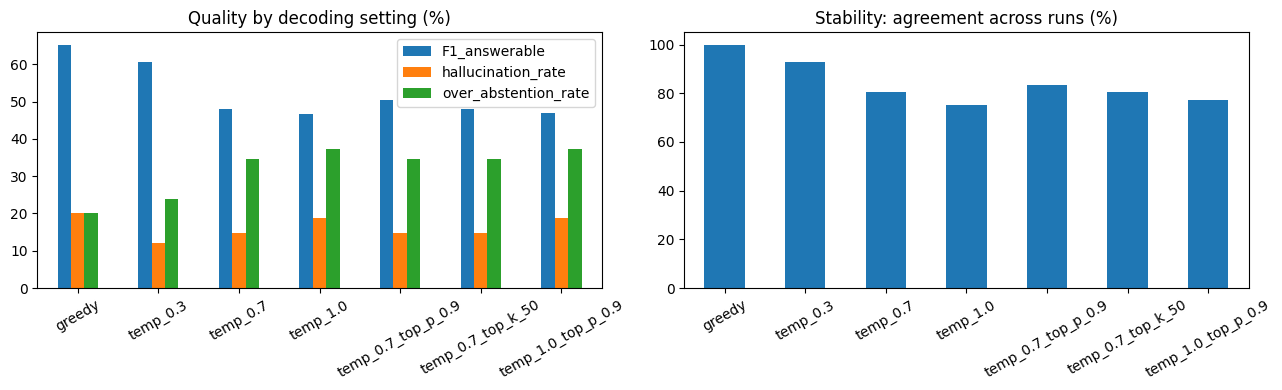

,question,decoding,run,pred_answer,error_type
4,How did the black death make it to the Mediter...,greedy,0,along the Silk Road,partial / over-long span
6,Along with non-governmental and nonstate schoo...,greedy,0,non-governmental,wrong answer
34,How did the black death make it to the Mediter...,greedy,1,along the Silk Road,partial / over-long span
36,Along with non-governmental and nonstate schoo...,greedy,1,non-governmental,wrong answer
4,How did the black death make it to the Mediter...,temp_0.3,0,along the Silk Road,partial / over-long span
...,...,...,...,...,...
66,Along with non-governmental and nonstate schoo...,temp_1.0_top_p_0.9,2,,over-abstention
94,How did the black death make it to the Mediter...,temp_1.0_top_p_0.9,3,"from there, it was most likely carried by Orie...",partial / over-long span
96,Along with non-governmental and nonstate schoo...,temp_1.0_top_p_0.9,3,non-governmental,wrong answer
124,How did the black death make it to the Mediter...,temp_1.0_top_p_0.9,4,along the Silk Road,partial / over-long span


In [9]:
import matplotlib.pyplot as plt

t = decoding_table.set_index('decoding')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
t[['F1_answerable', 'hallucination_rate', 'over_abstention_rate']].plot.bar(ax=axes[0], rot=30, title='Quality by decoding setting (%)')
t[['agreement']].plot.bar(ax=axes[1], rot=30, legend=False, title='Stability: agreement across runs (%)')
for ax in axes:
    ax.set_xlabel('')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/decoding_chart.png', dpi=200)
plt.show()

scored_dec = score_rows(decoding_results)
# pick the 2 questions whose answers changed most across runs at temperature 1.0
hot = scored_dec[scored_dec.decoding == 'temp_1.0']
most_varied = hot.groupby('id')['pred_answer'].nunique().sort_values(ascending=False).head(2).index
examples = scored_dec[scored_dec.id.isin(most_varied)][['question', 'decoding', 'run', 'pred_answer', 'error_type']]
examples.to_csv(f'{RESULTS_DIR}/summary_decoding_examples.csv', index=False)
examples

## Step 10 · Context-noise test (our distinct experiment)

**Question:** how much does irrelevant context hurt the model? This is the "context" theme in section 1 of the brief, and it's what makes our project different from other SQuAD groups.

**Design:** 100 questions (50 answerable + 50 unanswerable), greedy decoding, two conditions:

1. `clean` — only the correct paragraph
2. `noisy` — correct paragraph + 2 distractor paragraphs **from the same Wikipedia article**, in shuffled order (same-topic distractors are harder and more realistic than random ones, e.g. like a retriever returning near-misses)

*Why it matters for the project:* if we add a retrieval tool (the RAG step), the model will receive several paragraphs, not just the perfect one. This test measures the price of that.

⚠️ **Caveat to check by hand:** for an *unanswerable* question, a distractor paragraph might happen to contain the answer. Before calling a noisy-condition answer a hallucination, look at the flagged rows (printed below).

**Time:** about 10–12 minutes.

In [10]:
noise_rows = pd.concat([eval_df[eval_df.is_answerable].head(50),
                        eval_df[~eval_df.is_answerable].head(50)])


def make_noisy_context(r, k=2):
    rng = random.Random(f'{SEED}-{r.id}')                       # same distractors every time
    same_article = val_df[(val_df.title == r.title) & (val_df.context != r.context)].context.unique().tolist()
    pool = same_article if len(same_article) >= k else val_df[val_df.context != r.context].context.unique().tolist()
    paragraphs = rng.sample(pool, k) + [r.context]
    rng.shuffle(paragraphs)
    return '\n\n'.join(paragraphs)


clean = run_experiment('noise_clean', noise_rows, dict(do_sample=False))
noisy = run_experiment('noise_noisy', noise_rows, dict(do_sample=False), context_fn=make_noisy_context)

noise_table = compare_systems({'clean (1 paragraph)': clean, 'noisy (+2 distractors)': noisy})
noise_table.to_csv(f'{RESULTS_DIR}/summary_context_noise.csv')
display(noise_table)

# Rows to check by hand: hallucinations that happen ONLY with distractors (the ones the noise caused)
s_clean = score_rows(clean).set_index('id')
s_noisy = score_rows(noisy).set_index('id')
h_clean = set(s_clean[s_clean.error_type == 'hallucination'].index)
h_noisy = set(s_noisy[s_noisy.error_type == 'hallucination'].index)
print(f'Hallucinations: clean {len(h_clean)}, noisy {len(h_noisy)}, in both {len(h_clean & h_noisy)}, noisy-only {len(h_noisy - h_clean)}')
noisy_only = s_noisy.loc[sorted(h_noisy - h_clean), ['question', 'pred_answer', 'evidence']]
noisy_only.to_csv(f'{RESULTS_DIR}/summary_noise_only_hallucinations.csv')
noisy_only

noise_clean: already done - loading saved results
noise_noisy: already done - loading saved results


,n_questions,n_answerable,n_unanswerable,EM_overall,F1_overall,EM_answerable,F1_answerable,abstention_accuracy,hallucination_rate,over_abstention_rate,evidence_faithfulness,json_validity,flag_conflicts
clean (1 paragraph),100.0,50.0,50.0,70.0,73.6,68.0,75.1,72.0,28.0,16.0,82.1,94.0,0.0
noisy (+2 distractors),100.0,50.0,50.0,62.0,64.6,56.0,61.2,68.0,32.0,24.0,70.4,94.0,0.0


Hallucinations: clean 14, noisy 16, in both 12, noisy-only 4


,question,pred_answer,evidence
id,,,
5a8349a2e60761001a2eb50b,What do cnidarians use their combs for?,swimming,Their most distinctive feature is the ‘combs’ ...
5ad23fded7d075001a4288fc,When did the Huguenot movement start?,1562,Huguenot numbers peaked near an estimated two ...
5ad23fded7d075001a4288fd,Where were French Catholics concentrated in Fr...,mainly in the southern and central parts of Fr...,Huguenot numbers peaked near an estimated two ...
5ad39d53604f3c001a3fe8d3,Who did King Charles III swear fealty to?,King Charles III of West Francia,They were descended from Norse ('Norman' comes...


## Step 11 · Evaluate another notebook's CSV (e.g. the baseline from 02_prompting)

Put the CSV in `My Drive/GenAI_Group7/results/` (or upload it with the folder icon on the left), then set the file name below.

It only needs these columns: `id, context, gold_answers, is_answerable, raw_output` — any extra columns are fine.

**You should see:** the headline metrics dictionary and a count of error types.

In [11]:
OTHER_CSV = f'{RESULTS_DIR}/exp_prompt_baseline.csv'    # <- baseline from 02_prompting

if os.path.exists(OTHER_CSV):
    other = pd.read_csv(OTHER_CSV)
    display(pd.Series(evaluate(other)))
    display(score_rows(other)['error_type'].value_counts())
else:
    print('File not found yet:', OTHER_CSV)

,0
n_questions,200.0
n_answerable,100.0
n_unanswerable,100.0
EM_overall,52.5
F1_overall,62.5
EM_answerable,56.0
F1_answerable,76.0
abstention_accuracy,49.0
hallucination_rate,51.0
over_abstention_rate,0.0


,count
error_type,
correct,105
hallucination,51
partial / over-long span,35
wrong answer,9


## Step 12 · E6 Failure analysis — collect candidates from every experiment

The brief needs **at least 3 failure cases** in an analysis table. This cell gathers every wrong answer from all `exp_*` CSVs, groups them by error type, and saves them. You then pick the 3–5 most instructive ones (ideally one per type) and fill the table in the report:

| # | Question (short) | Expected | Model output | Error type | Likely cause | Fix / control |
|---|---|---|---|---|---|---|

Typical causes to look for: question shares words with the paragraph but asks about something not stated (hallucination); answer includes extra words (over-long span → lower F1); paragraph mentions several dates/names (distractor confusion); JSON broken by extra text.

In [12]:
all_files = sorted(glob.glob(f'{RESULTS_DIR}/exp_*.csv'))
parts = []
for f in all_files:
    d = pd.read_csv(f)
    d['experiment'] = os.path.basename(f)[4:-4]        # e.g. 'prompt_few_shot', 'temp_0.7', 'noise_noisy'
    parts.append(d)
scored_all = score_rows(pd.concat(parts, ignore_index=True))

failures = scored_all[scored_all.error_type != 'correct']
print(failures.groupby(['experiment', 'error_type']).size().unstack(fill_value=0))

candidates = (failures.drop_duplicates(subset=['id', 'error_type'])
              .groupby('error_type').head(3)
              [['error_type', 'experiment', 'question', 'gold_answers', 'pred_answer', 'evidence', 'json_valid', 'flag_conflict']])
candidates.to_csv(f'{RESULTS_DIR}/summary_failure_candidates.csv', index=False)
candidates

error_type          hallucination  over-abstention  partial / over-long span  \
experiment                                                                     
greedy                          6                6                         2   
noise_clean                    14                8                         5   
noise_noisy                    16               12                         4   
prompt_baseline                51                0                        35   
temp_0.3                        9               18                         5   
temp_0.7                       11               26                         6   
temp_0.7_top_k_50              11               26                         6   
temp_0.7_top_p_0.9             11               26                         3   
temp_1.0                       14               28                         7   
temp_1.0_top_p_0.9             14               28                         3   

error_type          wrong answer  
expe

,error_type,experiment,question,gold_answers,pred_answer,evidence,json_valid,flag_conflict
1,over-abstention,greedy,By what main attribute are computational probl...,"[inherent difficulty, their inherent difficult...",,Computational complexity theory is a branch of...,True,False
4,partial / over-long span,greedy,How did the black death make it to the Mediter...,"[merchant ships., merchant ships, Silk Road]",along the Silk Road,The Black Death is thought to have originated ...,True,False
6,wrong answer,greedy,Along with non-governmental and nonstate schoo...,"[independent, independent schools, independent...",non-governmental,"Private schools, also known as independent sch...",False,False
10,over-abstention,greedy,What does the UN want to stabilize?,[greenhouse gas concentrations in the atmosphe...,,The ultimate objective of the UNFCCC is to 'st...,True,False
11,wrong answer,greedy,When was the current parliament of Scotland co...,"[Following a referendum in 1997, 1998, 1998]",1999,The first meeting of the new Parliament took p...,True,False
13,over-abstention,greedy,What is the only divisor besides 1 that a prim...,"[itself, itself, itself, itself, itself]",,A prime number (or a prime) is a natural numbe...,True,False
15,hallucination,greedy,How large is the San Joaquin Valley?,[],approximately 220 miles (350 km) northwest of ...,Fresno is in the center of the San Joaquin Val...,True,False
16,hallucination,greedy,What did the concept hope to achieve?,[],"fault-tolerant, efficient routing method","Starting in the late 1950s, American computer ...",True,False
17,hallucination,greedy,What branch of theoretical computer class deal...,[],Computational complexity theory,Computational complexity theory is a branch of...,True,False
79,partial / over-long span,noise_clean,"Along with sport and art, what is a type of ta...","[academic, academic, academic]",academic scholarship,at some private schools students may be able t...,True,False


## Step 13 · Final evaluation → notebook 06

The comparison of the baseline (E1) with the final system (E7) is done in **notebook 06 (harness ablation)**, which scores every system on the same 200 questions with this notebook's metrics and adds the per-component ablation, the 3B-model comparison, the tool-mode results and the injection tests.

## Done — what goes to GitHub

Copy these from `My Drive/GenAI_Group7/results` into the repo's `results/` folder and push:
`summary_decoding_comparison.csv`, `summary_decoding_examples.csv`, `decoding_chart.png`, `summary_context_noise.csv`, `summary_failure_candidates.csv`, `summary_final_comparison.csv`, and all `exp_*.csv` files (they are the raw evidence / prompt log).